In [1]:
import autograd.numpy as anp
import math

In [2]:
# stock, should be anp array
beam_stock_prams = anp.array([5, 8, 15, 21, 30])
beam_stock_numbs = anp.array([3, 4, 8, 7, 5])

In [27]:
# cosine basis function
def basis_func_cosine(l, l_prev, l_cur, l_next):
    if l <= l_prev:
        return 0.0 * l
    elif l_prev < l <= l_cur:
        return (1 + anp.cos(math.pi * anp.abs(l - l_cur) / anp.abs(l_cur - l_prev))) / 2
    elif l_cur < l <= l_next:
        return (1 + anp.cos(math.pi * anp.abs(l - l_cur) / anp.abs(l_next - l_cur))) / 2
    else:
        return 0.0 * l

In [28]:
# test function
l = 18.0
l_cur = 15.0
l_prev = 8.0
l_next = 21.0
print(basis_func_cosine(l, l_prev, l_cur, l_next))
#compute gradient
from autograd import grad
grad_basis_func = grad(basis_func_cosine)
print(grad_basis_func(l, l_prev, l_cur, l_next))

0.5
-0.2617993877991494


In [25]:
# extend to 2D
beam_stock_prams_2d = anp.array([[3, 1], [3, 2], [5, 2], [15, 3], [15, 1], [30, 2]])
beam_stock_numbs_2d = anp.array([3, 4, 8, 7, 5, 6])

## Visualize `basis_func_smooth` and its gradient

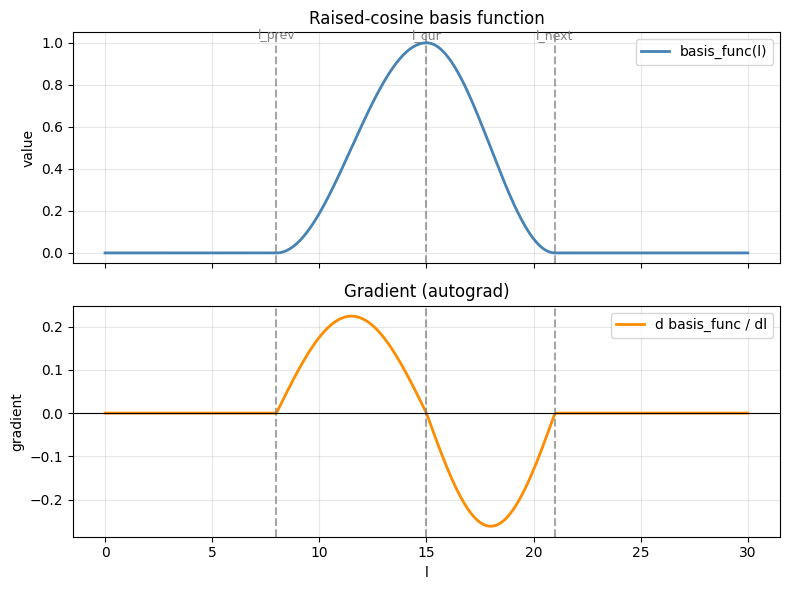

In [29]:
# visualize basis_func_smooth and its gradient over a range of l
import matplotlib.pyplot as plt
from autograd import grad

l_prev, l_cur, l_next = 8.0, 15.0, 21.0
l_vals = anp.linspace(0, 30, 400)

f_vals = anp.array([basis_func_cosine(l, l_prev, l_cur, l_next) for l in l_vals])

grad_basis_func = grad(basis_func_cosine)
g_vals = anp.array([grad_basis_func(l, l_prev, l_cur, l_next) for l in l_vals])

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

axes[0].plot(l_vals, f_vals, color='steelblue', lw=2, label='basis_func(l)')
for v, name in [(l_prev, 'l_prev'), (l_cur, 'l_cur'), (l_next, 'l_next')]:
    axes[0].axvline(v, ls='--', color='gray', alpha=0.7)
    axes[0].text(v, 1.02, name, ha='center', fontsize=9, color='gray')
axes[0].set_ylabel('value')
axes[0].set_title('Raised-cosine basis function')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(l_vals, g_vals, color='darkorange', lw=2, label='d basis_func / dl')
for v in (l_prev, l_cur, l_next):
    axes[1].axvline(v, ls='--', color='gray', alpha=0.7)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_xlabel('l')
axes[1].set_ylabel('gradient')
axes[1].set_title('Gradient (autograd)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Smooth cosine version of `basis_func_cosine`

- region 0: `l <= l_prev`  → value 0
- region 1: `l_prev < l <= l_cur` → rising cosine `v_left`
- region 2: `l_cur < l <= l_next` → falling cosine `v_right`
- region 3: `l > l_next` → value 0

In [30]:
# smooth version of basis_func
def smooth_basis_func_cosine(l, l_prev, l_cur, l_next, beta=10.0):
    h_left = anp.abs(l_cur - l_prev)
    h_right = anp.abs(l_next - l_cur)

    v_left = (1 + anp.cos(math.pi * anp.abs(l - l_cur) / h_left)) / 2
    v_right = (1 + anp.cos(math.pi * anp.abs(l - l_cur) / h_right)) / 2

    sig = lambda x: 1.0 / (1.0 + anp.exp(-beta * x))

    w0 = sig(l_prev - l)                    # l <= l_prev          -> 0
    w1 = sig(l - l_prev) * sig(l_cur - l)   # l_prev < l <= l_cur  -> v_left
    w2 = sig(l - l_cur) * sig(l_next - l)   # l_cur < l <= l_next  -> v_right
    w3 = sig(l - l_next)                    # l > l_next           -> 0

    w_sum = w0 + w1 + w2 + w3
    w_sum = w0 + w1 + w2 + w3
    return (w1 * v_left + w2 * v_right) / w_sum


print(basis_func_cosine(18.0, l_prev, l_cur, l_next))
print(smooth_basis_func_cosine(18.0, l_prev, l_cur, l_next, beta=50.0))


0.5
0.5


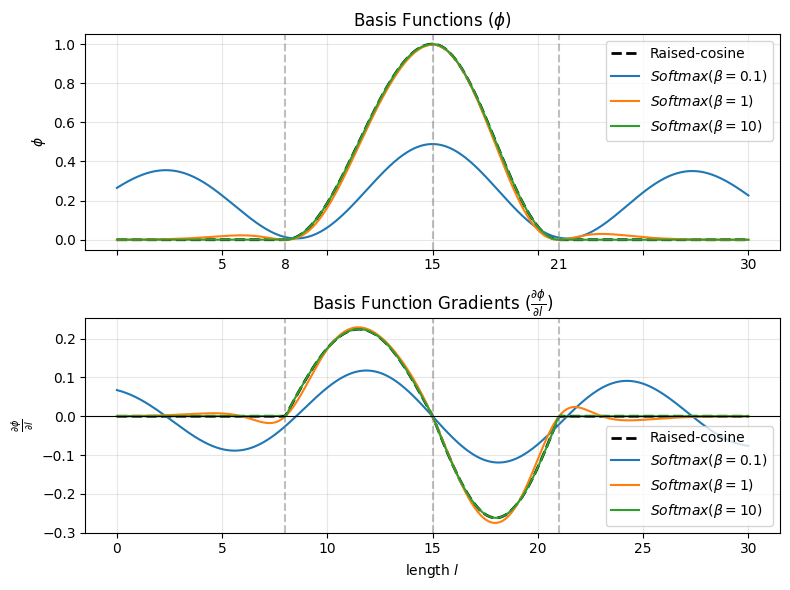

In [32]:
# compare basis_func_cosine vs smooth_basis_func_cosine
betas = [0.1, 1, 10]

grad_softmax_basis_func = grad(smooth_basis_func_cosine)

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

axes[0].plot(l_vals, f_vals, 'k--', lw=2, label='Raised-cosine')
axes[1].plot(l_vals, g_vals, 'k--', lw=2, label='Raised-cosine')

for b in betas:
    sf_vals = anp.array([smooth_basis_func_cosine(l, l_prev, l_cur, l_next, b) for l in l_vals])
    gsf_vals = anp.array([grad_softmax_basis_func(l, l_prev, l_cur, l_next, b) for l in l_vals])
    axes[0].plot(l_vals, sf_vals, lw=1.5, label=f'$Softmax (\\beta={b})$')
    axes[1].plot(l_vals, gsf_vals, lw=1.5, label=f'$Softmax (\\beta={b})$')


knots = [float(x) for x in beam_stock_prams]
for k in knots:
    # axes[0].axvline(k, ls='--', color='gray', alpha=0.4)
    axes[0].text(k, -0.15, f'{int(k)}', ha='center', fontsize=10, color='black')
    
for v in (l_prev, l_cur, l_next):
    axes[0].axvline(v, ls='--', color='gray', alpha=0.5)
    axes[1].axvline(v, ls='--', color='gray', alpha=0.5)

axes[0].set_ylabel('$\\phi$')
axes[0].set_title('Basis Functions $(\\phi)$')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_xlabel('length $l$')
axes[1].set_ylabel('$\\frac{{\\partial \\phi}}{{\\partial l}}$')
axes[1].set_title('Basis Function Gradients ($\\frac{{\\partial \\phi}}{{\\partial l}}$)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Gradient w.r.t. `l_cur`

/Users/cavers/miniconda3/envs/gp/lib/python3.10/site-packages/autograd/tracer.py:54: RuntimeWarning: divide by zero encountered in divide
  return f_raw(*args, **kwargs)
/Users/cavers/miniconda3/envs/gp/lib/python3.10/site-packages/autograd/tracer.py:54: RuntimeWarning: invalid value encountered in cos
  return f_raw(*args, **kwargs)
/Users/cavers/miniconda3/envs/gp/lib/python3.10/site-packages/autograd/tracer.py:54: RuntimeWarning: invalid value encountered in sin
  return f_raw(*args, **kwargs)


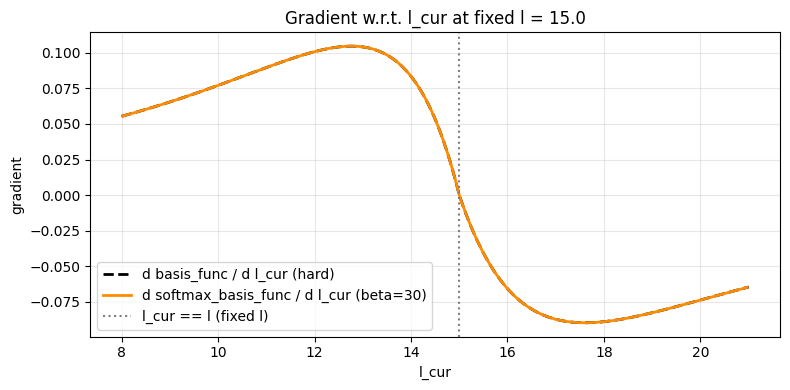

In [33]:
# gradient w.r.t. l_cur, for a fixed l, as l_cur sweeps across l
l_fixed = 15.0
l_cur_vals = anp.linspace(8.0, 21.0, 400)

grad_lcur_hard = grad(basis_func_cosine, argnum=2)
grad_lcur_soft = grad(smooth_basis_func_cosine, argnum=2)

g_hard = anp.array([grad_lcur_hard(l_fixed, 8.0, lc, 21.0) for lc in l_cur_vals])
g_soft = anp.array([grad_lcur_soft(l_fixed, 8.0, lc, 21.0, 30.0) for lc in l_cur_vals])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(l_cur_vals, g_hard, 'k--', lw=2, label='d basis_func / d l_cur (hard)')
ax.plot(l_cur_vals, g_soft, color='darkorange', lw=2, label='d softmax_basis_func / d l_cur (beta=30)')
ax.axvline(l_fixed, color='gray', ls=':', label='l_cur == l (fixed l)')
ax.set_xlabel('l_cur')
ax.set_ylabel('gradient')
ax.set_title(f'Gradient w.r.t. l_cur at fixed l = {l_fixed}')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Partition of unity: does $\sum_i \phi_i(l) \equiv 1$?

Build one basis function per knot in `beam_stock_prams = [5, 8, 15, 21, 30]`.
For an interior knot `i`, `(l_prev, l_cur, l_next) = (knots[i-1], knots[i], knots[i+1])`.
For the two boundary knots there is no neighbor on one side, so a "ghost" knot
is extrapolated (mirroring the adjacent spacing) so each boundary basis
function is still a full hat centered at its knot, peaking at 1 there.

In [35]:
knots = [float(x) for x in beam_stock_prams]

def get_neighbors(i, knots):
    l_cur = knots[i]
    if i == 0:
        l_prev = knots[0] - (knots[1] - knots[0])
    else:
        l_prev = knots[i - 1]
    if i == len(knots) - 1:
        l_next = knots[-1] + (knots[-1] - knots[-2])
    else:
        l_next = knots[i + 1]
    return l_prev, l_cur, l_next

triples = [get_neighbors(i, knots) for i in range(len(knots))]
for i, (lp, lc, ln) in enumerate(triples):
    print(f"phi_{i}: l_prev={lp}, l_cur={lc}, l_next={ln}")

l_plot = anp.linspace(knots[0], knots[-1], 600)

def basis_components_and_sum(func, triples, l_plot):
    comps = anp.array([[func(l, lp, lc, ln) for l in l_plot] for (lp, lc, ln) in triples])
    return comps, anp.sum(comps, axis=0)


phi_0: l_prev=2.0, l_cur=5.0, l_next=8.0
phi_1: l_prev=5.0, l_cur=8.0, l_next=15.0
phi_2: l_prev=8.0, l_cur=15.0, l_next=21.0
phi_3: l_prev=15.0, l_cur=21.0, l_next=30.0
phi_4: l_prev=21.0, l_cur=30.0, l_next=39.0


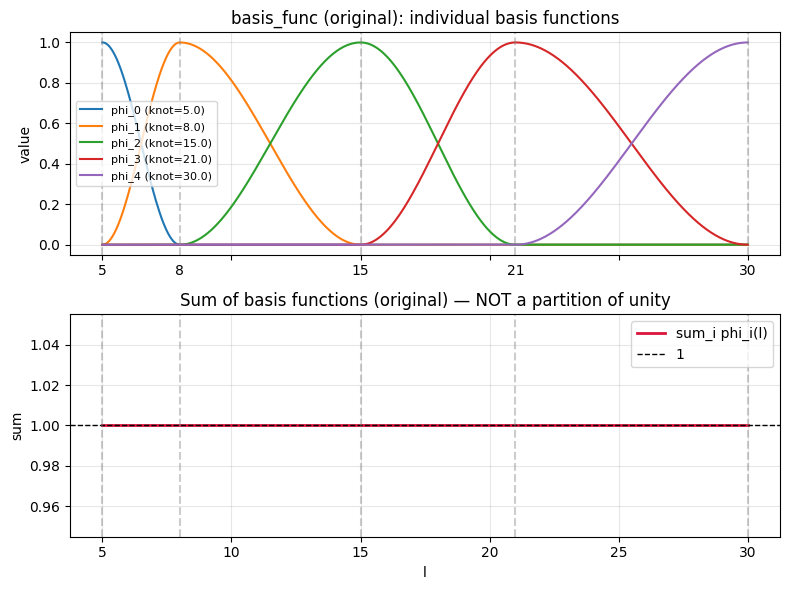

min/max of sum: 0.9999999999999998 1.0000000000000002


In [36]:
comps_orig, sum_orig = basis_components_and_sum(basis_func_cosine, triples, l_plot)

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

for i, comp in enumerate(comps_orig):
    axes[0].plot(l_plot, comp, label=f'phi_{i} (knot={knots[i]})')
for k in knots:
    axes[0].axvline(k, ls='--', color='gray', alpha=0.4)
    axes[0].text(k, -0.15, f'{int(k)}', ha='center', fontsize=10, color='black')
axes[0].set_ylabel('value')
axes[0].set_title('basis_func (original): individual basis functions')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(l_plot, sum_orig, color='crimson', lw=2, label='sum_i phi_i(l)')
axes[1].axhline(1.0, color='black', ls='--', lw=1, label='1')
for k in knots:
    axes[1].axvline(k, ls='--', color='gray', alpha=0.4)
axes[1].set_xlabel('l')
axes[1].set_ylabel('sum')
axes[1].set_title('Sum of basis functions (original) — NOT a partition of unity')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("min/max of sum:", float(anp.min(sum_orig)), float(anp.max(sum_orig)))


### Fixed basis function

As noted earlier, the right branch of `basis_func` rises 0 → 1 over
`(l_cur, l_next]` instead of falling 1 → 0. Swapping `l_next` for `l_cur` in
that branch's numerator turns each piece into a proper hat (raised-cosine)
function: 0 at `l_prev`, 1 at `l_cur`, 0 at `l_next`. With this fix, two
neighboring hats sum to exactly 1 across their shared interval — this is the
classic raised-cosine partition-of-unity identity
$\frac{1+\cos\theta}{2} + \frac{1+\cos(\pi-\theta)}{2} = 1$, and it holds for
*any* (non-uniform) knot spacing.

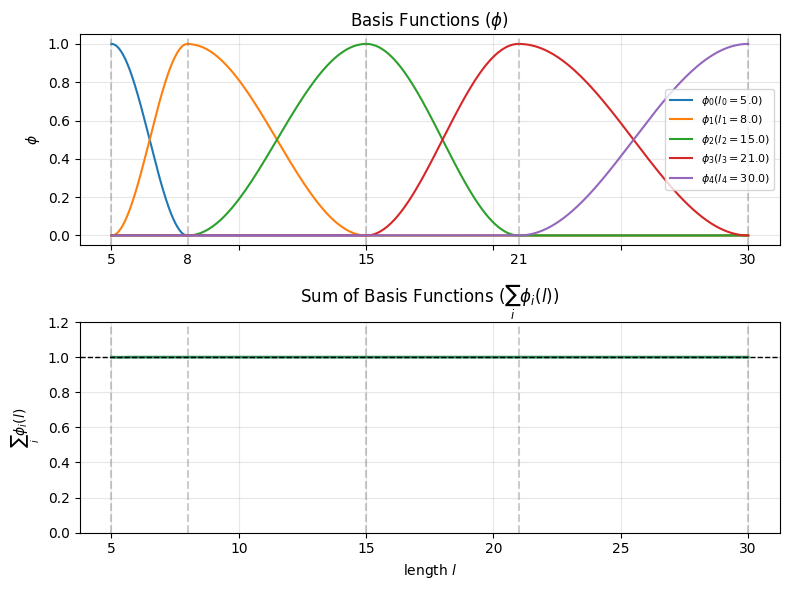

min/max of sum: 0.9986873592057852 1.0000000000000004


In [38]:
# fixed basis function: right branch now decreases 1 -> 0 over (l_cur, l_next]
def basis_func_fixed(l, l_prev, l_cur, l_next):
    if l <= l_prev:
        return 0.0 * l
    elif l_prev < l <= l_cur:
        return (1 + anp.cos(math.pi * anp.abs(l - l_cur) / anp.abs(l_cur - l_prev))) / 2
    elif l_cur < l <= l_next:
        return (1 + anp.cos(math.pi * anp.abs(l - l_cur) / anp.abs(l_next - l_cur))) / 2
    else:
        return 0.0 * l


comps_fixed, sum_fixed = basis_components_and_sum(smooth_basis_func_cosine, triples, l_plot)

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

for i, comp in enumerate(comps_fixed):
    axes[0].plot(l_plot, comp, label=f'$\\phi_{i} (l_{i}={knots[i]})$')
for k in knots:
    axes[0].axvline(k, ls='--', color='gray', alpha=0.4)
    axes[0].text(k, -0.15, f'{int(k)}', ha='center', fontsize=10, color='black')
axes[0].set_ylabel('$\\phi$')
axes[0].set_title('Basis Functions $(\\phi)$')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(l_plot, sum_fixed, color='seagreen', lw=2, label='$\\sum_i \\phi_i(l)$')
axes[1].axhline(1.0, color='black', ls='--', lw=1, label='1')
for k in knots:
    axes[1].axvline(k, ls='--', color='gray', alpha=0.4)
axes[1].set_xlabel('length $l$')
axes[1].set_ylabel('$\\sum_i \\phi_i(l)$')
axes[1].set_title('Sum of Basis Functions ($\\sum_i \\phi_i(l)$)')
axes[1].set_ylim(0, 1.2)
# axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("min/max of sum:", float(anp.min(sum_fixed)), float(anp.max(sum_fixed)))


## Check: is the autograd gradient of `basis_func_fixed` continuous?

For each breakpoint (`l_prev`, `l_cur`, `l_next`), evaluate the gradient just
below and just above the switch point — both for `d/dl` and for
`d/dl_cur` (a breakpoint position). If both sides agree, autograd's
piecewise gradient has no jump there.

In [ ]:
grad_l = grad(basis_func_fixed, argnum=0)
grad_lcur = grad(basis_func_fixed, argnum=2)
eps = 1e-7

print("d/dl at each breakpoint (left vs right limit):")
for name, x in [("l_prev", l_prev), ("l_cur", l_cur), ("l_next", l_next)]:
    gL = grad_l(x - eps, l_prev, l_cur, l_next)
    gR = grad_l(x + eps, l_prev, l_cur, l_next)
    print(f"  {name}={x}:  d/dl(-) = {gL: .3e}   d/dl(+) = {gR: .3e}")

print("\nd/dl_cur at l_cur == l (the branch-switch point), fixed l=15:")
l_fixed = 15.0
gL = grad_lcur(l_fixed, l_prev, l_fixed - eps, l_next)
gR = grad_lcur(l_fixed, l_prev, l_fixed + eps, l_next)
print(f"  d/dl_cur(-) = {gL: .3e}   d/dl_cur(+) = {gR: .3e}")
print("\n=> both sides ~0 at every breakpoint: gradient is continuous (C1),")
print("   unlike the original basis_func, where d/dl_cur jumps at l_cur == l.")


d/dl at each breakpoint (left vs right limit):
  l_prev=8.0:  d/dl(-) =  0.000e+00   d/dl(+) =  1.007e-08
  l_cur=15.0:  d/dl(-) =  1.007e-08   d/dl(+) = -1.371e-08
  l_next=21.0:  d/dl(-) = -1.371e-08   d/dl(+) =  0.000e+00

d/dl_cur at l_cur == l (the branch-switch point), fixed l=15:
  d/dl_cur(-) =  1.371e-08   d/dl_cur(+) = -1.007e-08

=> both sides ~0 at every breakpoint: gradient is continuous (C1),
   unlike the original basis_func, where d/dl_cur jumps at l_cur == l.


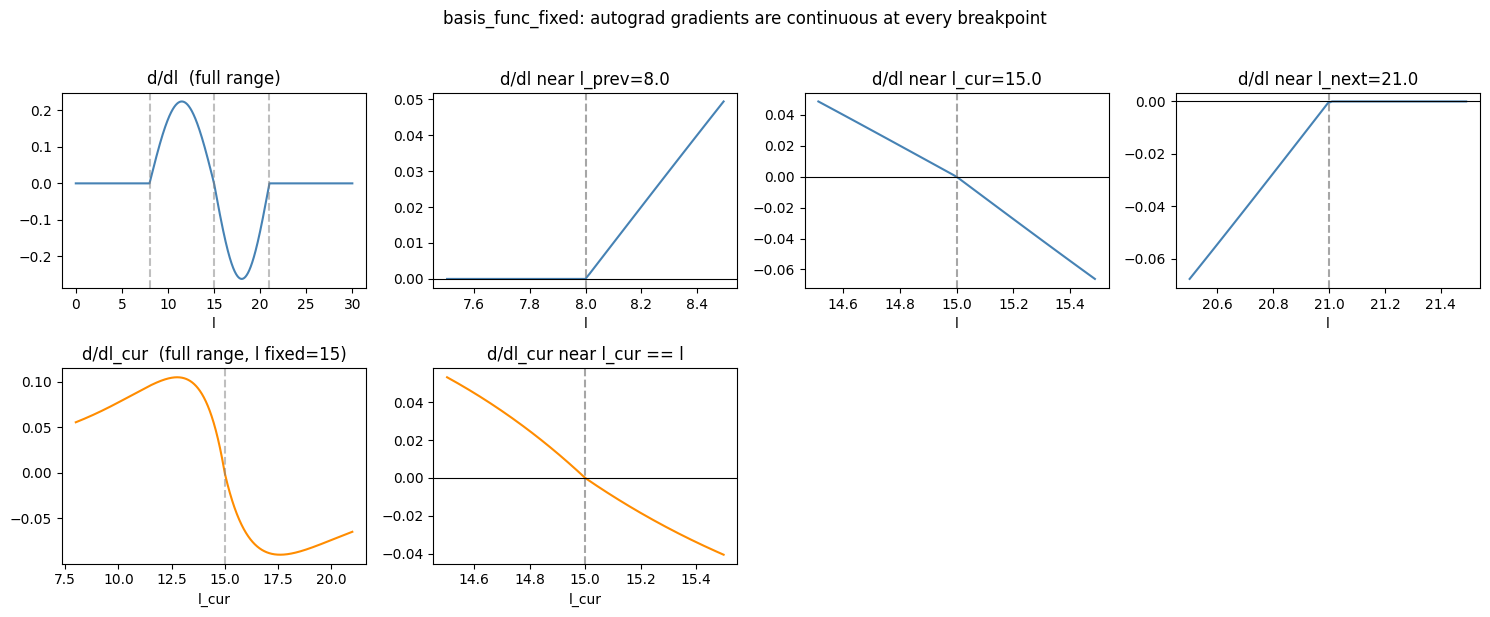

In [ ]:
zoom = 0.5

l_dense = anp.linspace(0, 30, 2000)
dl_vals = anp.array([grad_l(l, l_prev, l_cur, l_next) for l in l_dense])

lcur_dense = anp.linspace(8.0, 21.0, 2000)
dlcur_vals = anp.array([grad_lcur(l_fixed, l_prev, lc, l_next) for lc in lcur_dense])

fig, axes = plt.subplots(2, 4, figsize=(15, 6))

axes[0, 0].plot(l_dense, dl_vals, color='steelblue')
for v in (l_prev, l_cur, l_next):
    axes[0, 0].axvline(v, ls='--', color='gray', alpha=0.5)
axes[0, 0].set_title('d/dl  (full range)')
axes[0, 0].set_xlabel('l')

for ax, v, name in zip(axes[0, 1:], (l_prev, l_cur, l_next), ('l_prev', 'l_cur', 'l_next')):
    mask = (l_dense > v - zoom) & (l_dense < v + zoom)
    ax.plot(l_dense[mask], dl_vals[mask], color='steelblue')
    ax.axvline(v, ls='--', color='gray', alpha=0.7)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(f'd/dl near {name}={v}')
    ax.set_xlabel('l')

axes[1, 0].plot(lcur_dense, dlcur_vals, color='darkorange')
axes[1, 0].axvline(l_fixed, ls='--', color='gray', alpha=0.5)
axes[1, 0].set_title('d/dl_cur  (full range, l fixed=15)')
axes[1, 0].set_xlabel('l_cur')

mask = (lcur_dense > l_fixed - zoom) & (lcur_dense < l_fixed + zoom)
axes[1, 1].plot(lcur_dense[mask], dlcur_vals[mask], color='darkorange')
axes[1, 1].axvline(l_fixed, ls='--', color='gray', alpha=0.7)
axes[1, 1].axhline(0, color='black', lw=0.8)
axes[1, 1].set_title('d/dl_cur near l_cur == l')
axes[1, 1].set_xlabel('l_cur')

axes[1, 2].axis('off')
axes[1, 3].axis('off')

plt.suptitle('basis_func_fixed: autograd gradients are continuous at every breakpoint', y=1.02)
plt.tight_layout()
plt.show()


## Snap Energy: `basis_snap_energy`

Each basis function $\phi_i$ peaks at 1 at its stock knot and falls to 0 away from it.
We want an energy that is 0 at stock lengths and positive in between.

At a stock knot, one $\phi_k = 1$ and the rest $\approx 0$, so the log-sum-exp reaches its maximum:

$$S_{\max} = \frac{1}{\beta}\log(e^\beta + n - 1)$$

At any other point, the $\phi_i$ are more evenly spread, so log-sum-exp is smaller. We define:

$$\mathcal{L}_{\text{rounding}}(l) = \frac{1}{\beta}\log\frac{e^\beta + n-1}{\displaystyle\sum_i e^{\beta \phi_i(l)}}$$

This is exactly 0 at every stock knot, and positive in between. The `beta` parameter controls sharpness: larger `beta` → sharper attraction wells, closer to hard snap.

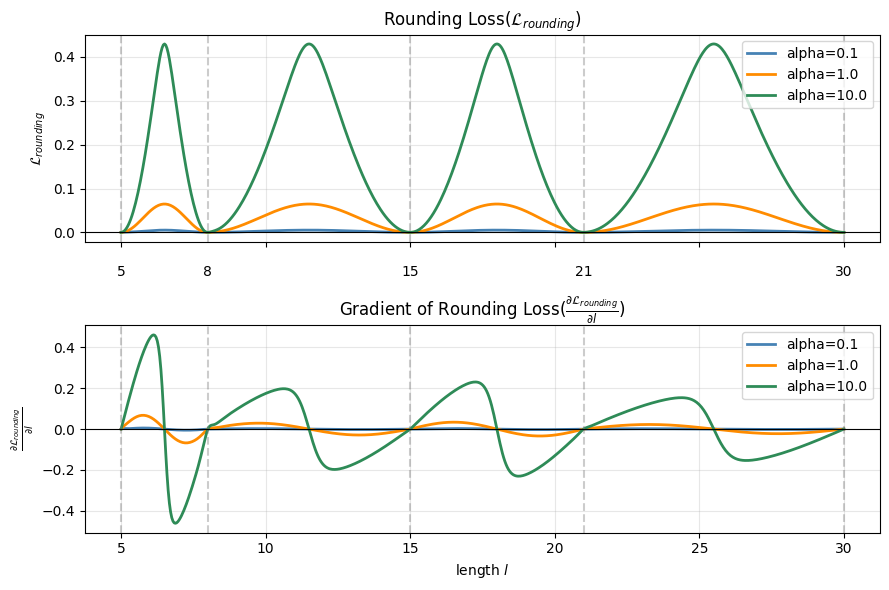

Energy at each stock knot (should be ~0):
  l=5:  E = 0.0000
  l=8:  E = 0.0000
  l=15:  E = 0.0000
  l=21:  E = 0.0000
  l=30:  E = 0.0000


In [ ]:
def basis_snap_energy(l, triples, alpha=5.0):
    phis = anp.array([softmax_basis_func(l, lp, lc, ln) for (lp, lc, ln) in triples])
    n = float(len(phis))
    soft_max_val = anp.log(anp.sum(anp.exp(alpha * phis))) / alpha
    knot_offset = anp.log(anp.exp(alpha * 1.0) + (n - 1) * anp.exp(alpha * 0.0)) / alpha
    peak = knot_offset - anp.log(anp.exp(0.5) + anp.exp(0.5)) / alpha
    return knot_offset - soft_max_val

import matplotlib.pyplot as plt
from autograd import grad

l_plot = anp.linspace(knots[0], knots[-1], 600)
alphas = [0.1, 1.0, 10.0]
colors = ['steelblue', 'darkorange', 'seagreen']

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

for alpha, color in zip(alphas, colors):
    e_vals = anp.array([basis_snap_energy(l, triples, alpha) for l in l_plot])
    grad_e  = grad(lambda l: basis_snap_energy(l, triples, alpha))
    g_vals  = anp.array([grad_e(l) for l in l_plot])

    axes[0].plot(l_plot, e_vals, color=color, lw=2, label=f'alpha={alpha}')
    axes[1].plot(l_plot, g_vals, color=color, lw=2, label=f'alpha={alpha}')

for k in knots:
    axes[0].axvline(k, ls='--', color='gray', alpha=0.4)
    axes[1].axvline(k, ls='--', color='gray', alpha=0.4)
    axes[0].text(k, -0.1, f'{int(k)}', ha='center', fontsize=10, color='black')

axes[0].axhline(0, color='black', lw=0.8)
axes[0].set_ylabel('${\\mathcal{L}_{rounding}}$')
axes[0].set_title('Rounding Loss(${\\mathcal{L}_{rounding}}$)')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_xlabel('length $l$')
axes[1].set_ylabel('$\\frac{\\partial {\\mathcal{L}_{rounding}}}{\\partial l}$')
axes[1].set_title('Gradient of Rounding Loss($\\frac{\\partial {\\mathcal{L}_{rounding}}}{\\partial l}$)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print('Energy at each stock knot (should be ~0):')
for k in knots:
    print(f'  l={k:.0f}:  E = {basis_snap_energy(float(k), triples, alpha=5.0):.4f}')

## Pure Softmax Basis Function

A direct softmax over negative distances to each stock knot:

$$B_i(\ell) = \frac{e^{-\beta |\ell - l(b_i)|}}{\sum_j e^{-\beta |\ell - l(b_j)|}}$$

This satisfies **Partition of Unity** (condition 3) exactly by construction,
and **Monotonicity** (condition 2) on each side. However, condition (1) (Interpolation)
only holds in the limit $\beta \to \infty$: at a knot $l(b_i)$,
$B_i = e^0 / (e^0 + \sum_{j\neq i} e^{-\beta|l(b_i)-l(b_j)|})$,
which approaches 1 as $\beta$ grows but is never exactly 1 for finite $\beta$.

In [41]:
import autograd.numpy as anp
import math
import matplotlib.pyplot as plt
from autograd import grad

beam_stock_prams = anp.array([5, 8, 15, 21, 30])
knots = [float(x) for x in beam_stock_prams]

def softmax_pure_basis_func(l, knots, i, beta=5.0):
    dists = anp.array([anp.abs(l - lj) for lj in knots])
    logits = -beta * dists
    logits_shifted = logits - anp.max(logits)
    exp_logits = anp.exp(logits_shifted)
    return exp_logits[i] / anp.sum(exp_logits)


print("Partition of unity check (should be 1.0 everywhere):")
for l_test in [5.0, 10.0, 15.0, 18.0, 30.0]:
    total = sum(softmax_pure_basis_func(l_test, knots, i, beta=5.0) for i in range(len(knots)))
    print(f"  l={l_test:.1f}: sum = {total:.6f}")

print("\nInterpolation check at knot l=15 (knot index 2):")
for beta in [1, 5, 10, 50]:
    vals = [softmax_pure_basis_func(15.0, knots, i, beta=beta) for i in range(len(knots))]
    print(f"  beta={beta:3d}: B_2(15) = {vals[2]:.4f}, others = {[f'{v:.4f}' for j,v in enumerate(vals) if j!=2]}")


Partition of unity check (should be 1.0 everywhere):
  l=5.0: sum = 1.000000
  l=10.0: sum = 1.000000
  l=15.0: sum = 1.000000
  l=18.0: sum = 1.000000
  l=30.0: sum = 1.000000

Interpolation check at knot l=15 (knot index 2):
  beta=  1: B_2(15) = 0.9966, others = ['0.0000', '0.0009', '0.0025', '0.0000']
  beta=  5: B_2(15) = 1.0000, others = ['0.0000', '0.0000', '0.0000', '0.0000']
  beta= 10: B_2(15) = 1.0000, others = ['0.0000', '0.0000', '0.0000', '0.0000']
  beta= 50: B_2(15) = 1.0000, others = ['0.0000', '0.0000', '0.0000', '0.0000']


### Visualize Pure Softmax: all basis functions + partition of unity

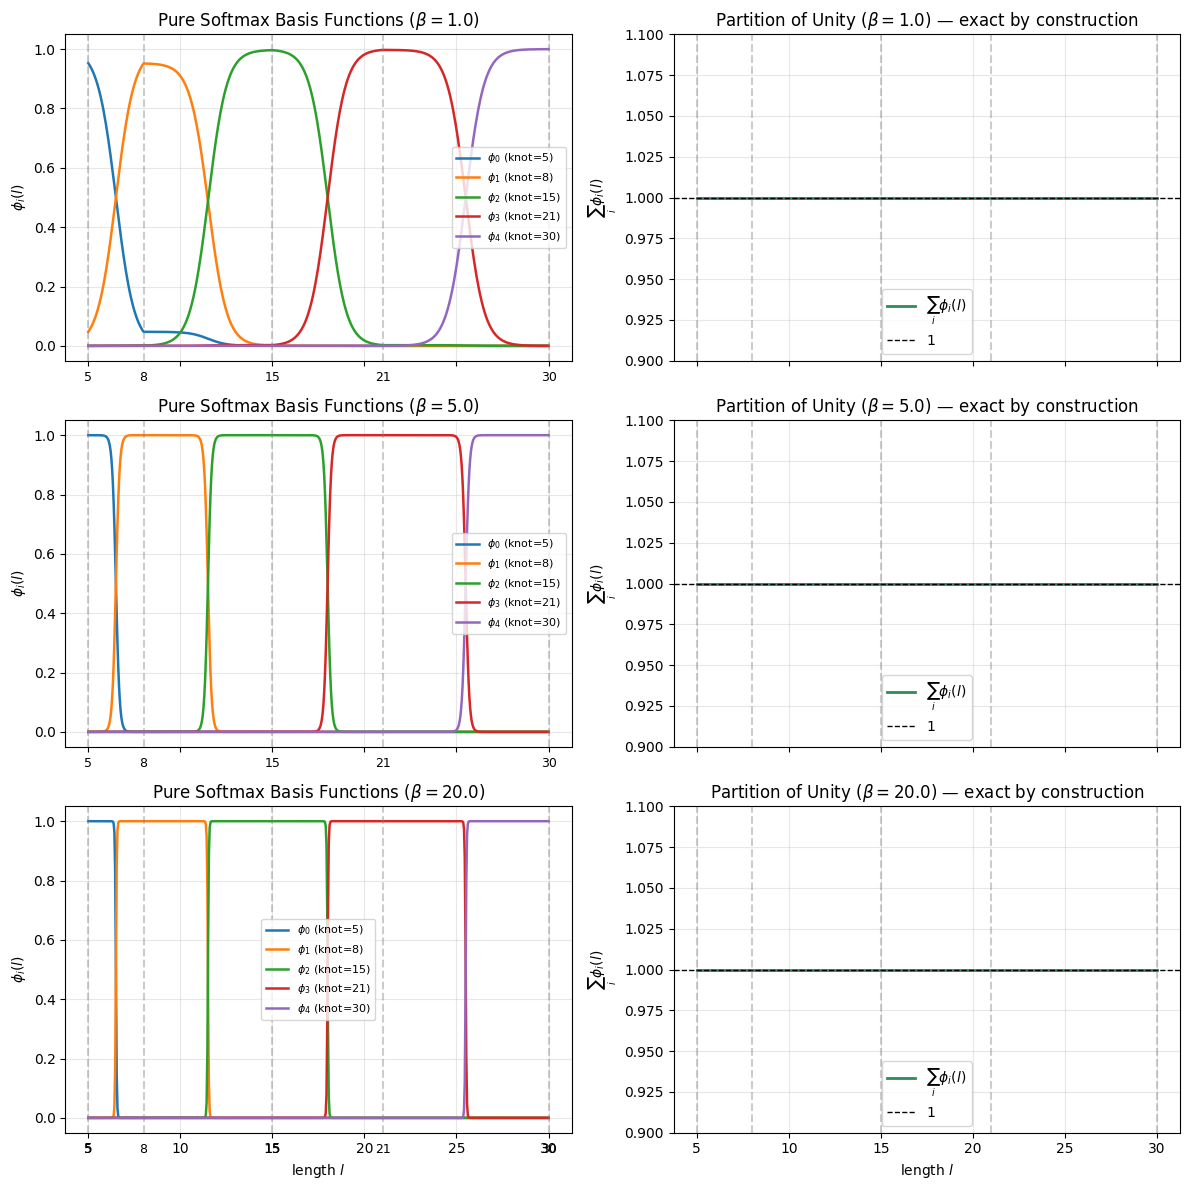

In [42]:
betas = [1.0, 5.0, 20.0]
l_plot = anp.linspace(knots[0], knots[-1], 600)

fig, axes = plt.subplots(len(betas), 2, figsize=(12, 4 * len(betas)), sharex=True)

for row, beta in enumerate(betas):
    # individual basis functions
    comps = anp.array([
        [softmax_pure_basis_func(l, knots, i, beta) for l in l_plot]
        for i in range(len(knots))
    ])
    pou = anp.sum(comps, axis=0)  # should be identically 1

    ax0 = axes[row, 0]
    for i, comp in enumerate(comps):
        ax0.plot(l_plot, comp, lw=1.8, label=f'$\\phi_{i}$ (knot={int(knots[i])})')
    for k in knots:
        ax0.axvline(k, ls='--', color='gray', alpha=0.4)
        ax0.text(k, -0.12, f'{int(k)}', ha='center', fontsize=9, color='black')
    ax0.set_ylabel('$\\phi_i(l)$')
    ax0.set_title(f'Pure Softmax Basis Functions ($\\beta={beta}$)')
    ax0.legend(fontsize=8)
    ax0.grid(alpha=0.3)

    ax1 = axes[row, 1]
    ax1.plot(l_plot, pou, color='seagreen', lw=2, label='$\\sum_i \\phi_i(l)$')
    ax1.axhline(1.0, color='black', ls='--', lw=1, label='1')
    for k in knots:
        ax1.axvline(k, ls='--', color='gray', alpha=0.4)
    ax1.set_ylabel('$\\sum_i \\phi_i(l)$')
    ax1.set_title(f'Partition of Unity ($\\beta={beta}$) — exact by construction')
    ax1.set_ylim(0.9, 1.1)
    ax1.legend()
    ax1.grid(alpha=0.3)

axes[-1, 0].set_xlabel('length $l$')
axes[-1, 1].set_xlabel('length $l$')
plt.tight_layout()
plt.show()


### Compare gradient of pure softmax vs raised-cosine (softmax-gated)

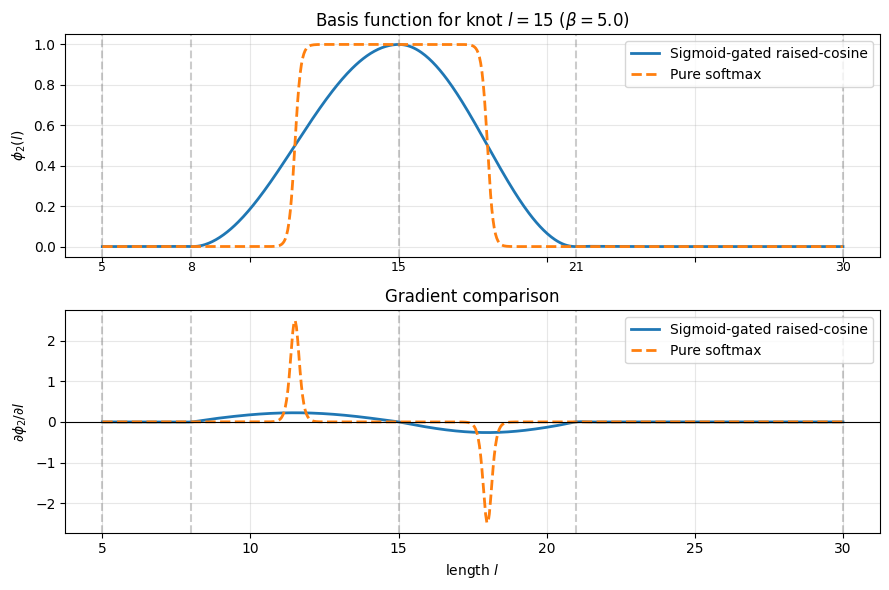

In [43]:
# pick knot i=2 (l_cur=15) and compare gradients across methods
i_ref = 2  # knot at l=15

def get_neighbors(i, knots):
    l_cur = knots[i]
    l_prev = knots[i-1] if i > 0 else knots[0] - (knots[1] - knots[0])
    l_next = knots[i+1] if i < len(knots)-1 else knots[-1] + (knots[-1] - knots[-2])
    return l_prev, l_cur, l_next

triples = [get_neighbors(i, knots) for i in range(len(knots))]
lp, lc, ln = triples[i_ref]

beta = 5.0

f_raised  = anp.array([softmax_basis_func(l, lp, lc, ln, beta=beta) for l in l_plot])
f_softmax = anp.array([softmax_pure_basis_func(l, knots, i_ref, beta=beta) for l in l_plot])

g_raised  = anp.array([grad(softmax_basis_func)(l, lp, lc, ln, beta) for l in l_plot])
g_softmax = anp.array([grad(lambda l: softmax_pure_basis_func(l, knots, i_ref, beta))(l) for l in l_plot])

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

axes[0].plot(l_plot, f_raised,  lw=2, label='Sigmoid-gated raised-cosine')
axes[0].plot(l_plot, f_softmax, lw=2, linestyle='--', label='Pure softmax')
for k in knots:
    axes[0].axvline(k, ls='--', color='gray', alpha=0.4)
    axes[0].text(k, -0.12, f'{int(k)}', ha='center', fontsize=9)
axes[0].set_ylabel('$\\phi_{2}(l)$')
axes[0].set_title(f'Basis function for knot $l=15$ ($\\beta={beta}$)')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(l_plot, g_raised,  lw=2, label='Sigmoid-gated raised-cosine')
axes[1].plot(l_plot, g_softmax, lw=2, linestyle='--', label='Pure softmax')
for k in knots:
    axes[1].axvline(k, ls='--', color='gray', alpha=0.4)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_xlabel('length $l$')
axes[1].set_ylabel('$\\partial \\phi_{2} / \\partial l$')
axes[1].set_title('Gradient comparison')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Linear Hat Basis Function

The classic piecewise-linear hat function centered at knot $l_i$:

$$B_i(\ell) = \begin{cases}
0 & \ell \leq l_{i-1} \\
\dfrac{\ell - l_{i-1}}{l_i - l_{i-1}} & l_{i-1} < \ell \leq l_i \\
\dfrac{l_{i+1} - \ell}{l_{i+1} - l_i} & l_i < \ell \leq l_{i+1} \\
0 & \ell > l_{i+1}
\end{cases}$$

Neighboring hat functions sum to exactly 1 across any shared interval
(classic partition-of-unity identity for linear FEM shape functions),
so condition (3) is satisfied exactly. Conditions (1) and (2) are also
satisfied exactly, but the gradient is piecewise-constant (discontinuous
at the breakpoints), unlike the raised-cosine or softmax versions.

In [46]:
import autograd.numpy as anp
import math
import matplotlib.pyplot as plt
from autograd import grad

beam_stock_prams = anp.array([5, 8, 15, 21, 30])
knots = [float(x) for x in beam_stock_prams]

def linear_hat_basis_func(l, l_prev, l_cur, l_next):
    if l <= l_prev:
        return 0.0 * l
    elif l_prev < l <= l_cur:
        return (l - l_prev) / anp.abs(l_cur - l_prev)
    elif l_cur < l <= l_next:
        return (l_next - l) / anp.abs(l_next - l_cur)
    else:
        return 0.0 * l


def get_neighbors(i, knots):
    l_cur = knots[i]
    l_prev = knots[i-1] if i > 0 else knots[0] - (knots[1] - knots[0])
    l_next = knots[i+1] if i < len(knots)-1 else knots[-1] + (knots[-1] - knots[-2])
    return l_prev, l_cur, l_next

triples = [get_neighbors(i, knots) for i in range(len(knots))]

print("Condition (1) — Interpolation:")
for i, (lp, lc, ln) in enumerate(triples):
    print(f"  B_{i}(l_{i}={lc:.0f}) = {linear_hat_basis_func(lc, lp, lc, ln):.4f}  (expected 1)")

print("\nCondition (1) — vanishes at other knots (B_2 at all knots):")
lp2, lc2, ln2 = triples[2]
for k in knots:
    print(f"  B_2({k:.0f}) = {linear_hat_basis_func(k, lp2, lc2, ln2):.4f}")

print("\nCondition (3) — Partition of unity:")
l_plot = anp.linspace(knots[0], knots[-1], 600)
pou = anp.array([
    sum(linear_hat_basis_func(l, lp, lc, ln) for (lp, lc, ln) in triples)
    for l in l_plot
])
print(f"  min={float(anp.min(pou)):.6f}, max={float(anp.max(pou)):.6f}  (expected 1.0 everywhere)")


Condition (1) — Interpolation:
  B_0(l_0=5) = 1.0000  (expected 1)
  B_1(l_1=8) = 1.0000  (expected 1)
  B_2(l_2=15) = 1.0000  (expected 1)
  B_3(l_3=21) = 1.0000  (expected 1)
  B_4(l_4=30) = 1.0000  (expected 1)

Condition (1) — vanishes at other knots (B_2 at all knots):
  B_2(5) = 0.0000
  B_2(8) = 0.0000
  B_2(15) = 1.0000
  B_2(21) = 0.0000
  B_2(30) = 0.0000

Condition (3) — Partition of unity:
  min=1.000000, max=1.000000  (expected 1.0 everywhere)


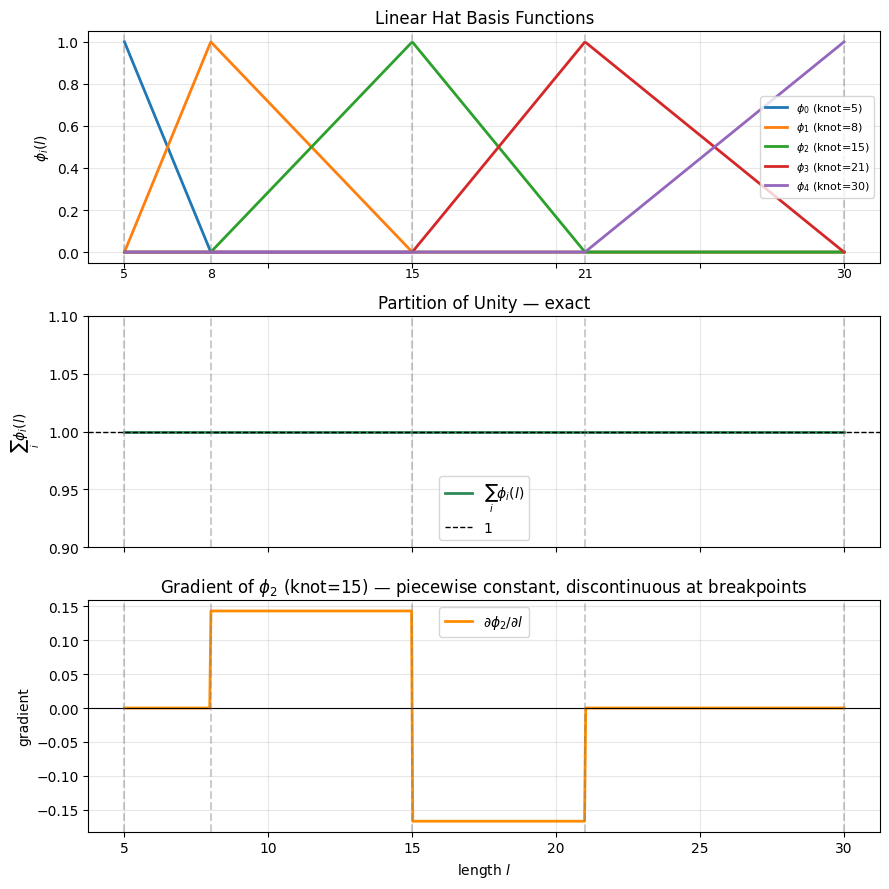

In [48]:
comps = anp.array([
    [linear_hat_basis_func(l, lp, lc, ln) for l in l_plot]
    for (lp, lc, ln) in triples
])
pou = anp.sum(comps, axis=0)

grad_hat = grad(linear_hat_basis_func)
lp2, lc2, ln2 = triples[2]
g_hat = anp.array([grad_hat(l, lp2, lc2, ln2) for l in l_plot])

fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)

for i, comp in enumerate(comps):
    axes[0].plot(l_plot, comp, lw=2, label=f'$\\phi_{i}$ (knot={int(knots[i])})')
for k in knots:
    axes[0].axvline(k, ls='--', color='gray', alpha=0.4)
    axes[0].text(k, -0.12, f'{int(k)}', ha='center', fontsize=9, color='black')
axes[0].set_ylabel('$\\phi_i(l)$')
axes[0].set_title('Linear Hat Basis Functions')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(l_plot, pou, color='seagreen', lw=2, label='$\\sum_i \\phi_i(l)$')
axes[1].axhline(1.0, color='black', ls='--', lw=1, label='1')
for k in knots:
    axes[1].axvline(k, ls='--', color='gray', alpha=0.4)
axes[1].set_ylim(0.9, 1.1)
axes[1].set_ylabel('$\\sum_i \\phi_i(l)$')
axes[1].set_title('Partition of Unity — exact')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(l_plot, g_hat, color='darkorange', lw=2, label='$\\partial \\phi_2 / \\partial l$')
axes[2].axhline(0, color='black', lw=0.8)
for k in knots:
    axes[2].axvline(k, ls='--', color='gray', alpha=0.4)
axes[2].set_xlabel('length $l$')
axes[2].set_ylabel('gradient')
axes[2].set_title('Gradient of $\\phi_2$ (knot=15) — piecewise constant, discontinuous at breakpoints')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


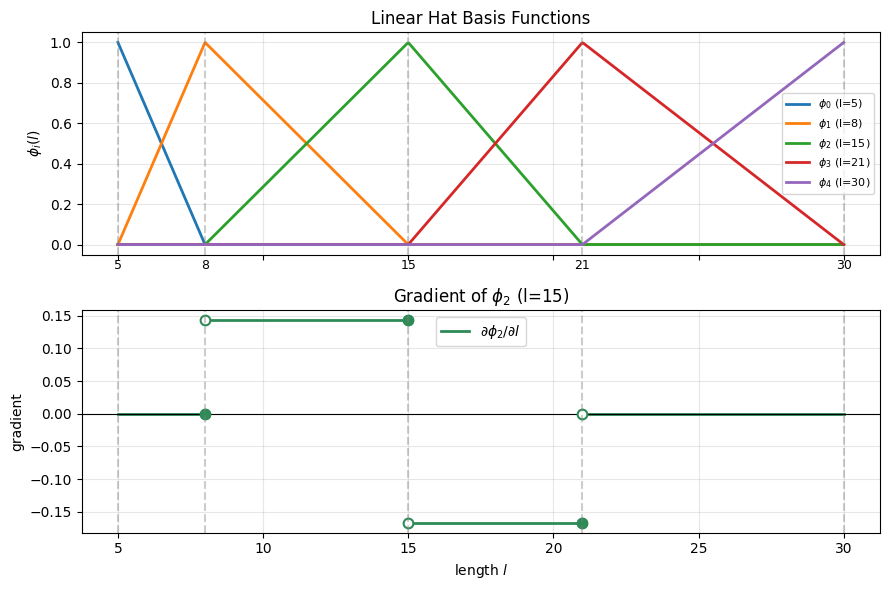

In [50]:
comps = anp.array([
    [linear_hat_basis_func(l, lp, lc, ln) for l in l_plot]
    for (lp, lc, ln) in triples
])

grad_hat = grad(linear_hat_basis_func)
lp2, lc2, ln2 = triples[2]
breakpoints = [lp2, lc2, ln2]
eps = 1e-6
dx = float(l_plot[1] - l_plot[0])
g_hat = anp.array([
    float('nan') if any(abs(l - bp) < dx for bp in breakpoints)
    else grad_hat(l, lp2, lc2, ln2)
    for l in l_plot
])

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

for i, comp in enumerate(comps):
    axes[0].plot(l_plot, comp, lw=2, label=f'$\\phi_{i}$ (l={int(knots[i])})')
for k in knots:
    axes[0].axvline(k, ls='--', color='gray', alpha=0.4)
    axes[0].text(k, -0.12, f'{int(k)}', ha='center', fontsize=9, color='black')
axes[0].set_ylabel('$\\phi_i(l)$')
axes[0].set_title('Linear Hat Basis Functions')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(l_plot, g_hat, color='seagreen', lw=2, label='$\\partial \\phi_2 / \\partial l$')
axes[1].axhline(0, color='black', lw=0.8)

for bp in breakpoints:
    g_left  = grad_hat(bp - eps, lp2, lc2, ln2)
    g_right = grad_hat(bp + eps, lp2, lc2, ln2)
    g_actual = grad_hat(bp, lp2, lc2, ln2)
    axes[1].plot(bp, g_left,   'o', color='seagreen', markersize=7,
                 markerfacecolor='white', markeredgewidth=1.5)
    axes[1].plot(bp, g_right,  'o', color='seagreen', markersize=7,
                 markerfacecolor='white', markeredgewidth=1.5)
    axes[1].plot(bp, g_actual, 'o', color='seagreen', markersize=7)

for k in knots:
    axes[1].axvline(k, ls='--', color='gray', alpha=0.4)
axes[1].set_xlabel('length $l$')
axes[1].set_ylabel('gradient')
axes[1].set_title('Gradient of $\\phi_2$ (l=15)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Compare all three basis function families

| Property | Raised-cosine (sigmoid-gated) | Pure softmax | Linear hat |
|---|---|---|---|
| Interpolation (1) | ✅ approx ($\beta\to\infty$) | ✅ approx ($\beta\to\infty$) | ✅ exact |
| Monotonicity (2) | ✅ | ✅ | ✅ exact |
| Partition of unity (3) | ❌ | ✅ exact | ✅ exact |
| $C^1$ differentiable | ✅ | ✅ | ❌ (kink at breakpoints) |

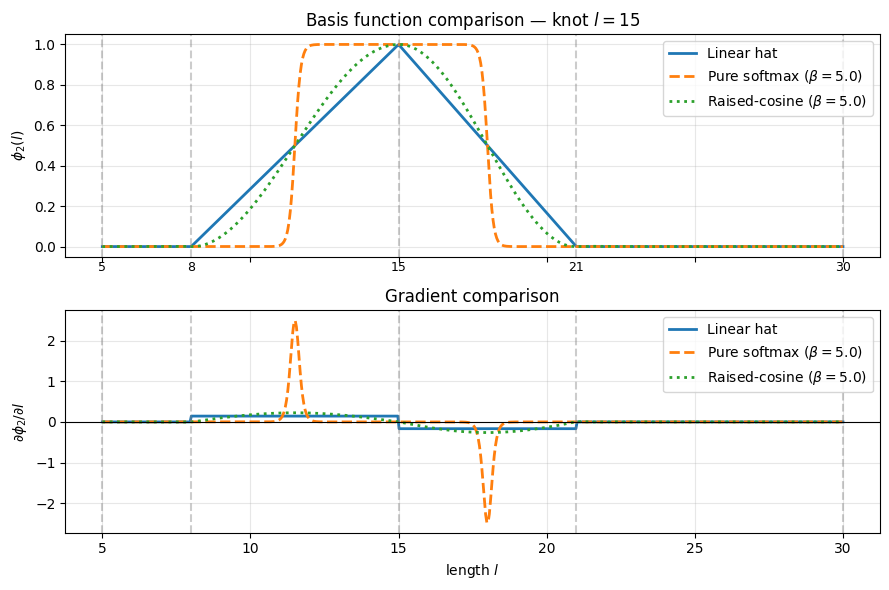

In [51]:
# side-by-side comparison of B_2 (knot=15) across all three families
def softmax_pure_basis_func(l, knots, i, beta=5.0):
    dists = anp.array([anp.abs(l - lj) for lj in knots])
    logits = -beta * dists
    logits_shifted = logits - anp.max(logits)
    exp_logits = anp.exp(logits_shifted)
    return exp_logits[i] / anp.sum(exp_logits)

def softmax_basis_func(l, l_prev, l_cur, l_next, beta=10.0):
    h_left  = anp.abs(l_cur - l_prev)
    h_right = anp.abs(l_next - l_cur)
    v_left  = (1 + anp.cos(math.pi * anp.abs(l - l_cur) / h_left))  / 2
    v_right = (1 + anp.cos(math.pi * anp.abs(l - l_cur) / h_right)) / 2
    sig = lambda x: 1.0 / (1.0 + anp.exp(-beta * x))
    w0 = sig(l_prev - l)
    w1 = sig(l - l_prev) * sig(l_cur - l)
    w2 = sig(l - l_cur)  * sig(l_next - l)
    w3 = sig(l - l_next)
    w_sum = w0 + w1 + w2 + w3
    return (w1 * v_left + w2 * v_right) / w_sum

beta = 5.0
lp2, lc2, ln2 = triples[2]

f_hat     = anp.array([linear_hat_basis_func(l, lp2, lc2, ln2) for l in l_plot])
f_softmax = anp.array([softmax_pure_basis_func(l, knots, 2, beta) for l in l_plot])
f_raised  = anp.array([softmax_basis_func(l, lp2, lc2, ln2, beta) for l in l_plot])

g_hat2    = anp.array([grad(linear_hat_basis_func)(l, lp2, lc2, ln2) for l in l_plot])
g_softmax2= anp.array([grad(lambda l: softmax_pure_basis_func(l, knots, 2, beta))(l) for l in l_plot])
g_raised2 = anp.array([grad(softmax_basis_func)(l, lp2, lc2, ln2, beta) for l in l_plot])

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

axes[0].plot(l_plot, f_hat,     lw=2,              label='Linear hat')
axes[0].plot(l_plot, f_softmax, lw=2, ls='--',     label=f'Pure softmax ($\\beta={beta}$)')
axes[0].plot(l_plot, f_raised,  lw=2, ls=':',      label=f'Raised-cosine ($\\beta={beta}$)')
for k in knots:
    axes[0].axvline(k, ls='--', color='gray', alpha=0.4)
    axes[0].text(k, -0.12, f'{int(k)}', ha='center', fontsize=9)
axes[0].set_ylabel('$\\phi_2(l)$')
axes[0].set_title('Basis function comparison — knot $l=15$')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(l_plot, g_hat2,     lw=2,          label='Linear hat')
axes[1].plot(l_plot, g_softmax2, lw=2, ls='--', label=f'Pure softmax ($\\beta={beta}$)')
axes[1].plot(l_plot, g_raised2,  lw=2, ls=':',  label=f'Raised-cosine ($\\beta={beta}$)')
for k in knots:
    axes[1].axvline(k, ls='--', color='gray', alpha=0.4)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_xlabel('length $l$')
axes[1].set_ylabel('$\\partial \\phi_2 / \\partial l$')
axes[1].set_title('Gradient comparison')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()
